# **실습 개요**

여러분은 핀테크 회사 '핀트러스트(가상)'의 대출 심사팀에 합류한 데이터 분석가입니다.<br>
회사는 개인 신용대출 상품을 운영하고 있으며,<br>대출 신청자의 정보를 바탕으로 **부도(상환 불이행) 가능성**을 사전에
예측하여 심사 담당자를 지원하는 모델을 만들어야 합니다.

정확한 부도 예측은 무분별한 대출 승인으로 인한 손실을 막는 동시에, <br>상환 능력이 충분한 고객에게는
더 빠르고 유리한 조건으로 대출을 제공할 수 있게 해줍니다.
## **데이터셋 설명**

| 컬럼명 | 설명 |
|---|---|
| applicant_id | 대출 신청자 고유 ID |
| age | 신청자 나이 |
| annual_income | 연소득 (원) |
| employment_years | 재직 연수 |
| credit_score | 신용점수 (300~850) |
| home_ownership | 주거 형태 (RENT=임차, MORTGAGE=담보대출 보유, OWN=자가) |
| loan_purpose | 대출 목적 (부채통합, 주택개선, 사업자금, 의료비, 교육, 자동차구입, 기타) |
| loan_amount | 대출 신청 금액 (원) |
| loan_term_months | 대출 상환 기간 (개월) |
| interest_rate | 적용 금리 (%) |
| debt_to_income_ratio | 부채 대비 소득 비율 (DTI) |
| loan_to_income_ratio | 대출금액 대비 연소득 비율 |
| num_credit_lines | 보유 신용거래(카드/대출 등) 개수 |
| previous_defaults | 과거 부도 이력 횟수 |
| is_default | **[target]** 부도 여부 (0 = 정상 상환, 1 = 부도) |

## **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/loan.csv

## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

**Q1. 필요한 라이브러리를 불러오고, loan_default.csv를 읽어온 뒤 첫 5개의 행을 출력하세요.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/loan.csv')
df.head()

,applicant_id,age,annual_income,employment_years,credit_score,home_ownership,loan_purpose,loan_amount,loan_term_months,interest_rate,debt_to_income_ratio,loan_to_income_ratio,num_credit_lines,previous_defaults,is_default
0,200945,63,72110000.0,10.6,655.0,MORTGAGE,사업자금,17970000.0,48,10.77,0.248,0.249,8,1,0
1,200974,39,23760000.0,8.9,NaN,RENT,의료비,13530000.0,60,12.77,0.497,0.569,6,0,1
2,200151,62,42900000.0,9.2,657.0,MORTGAGE,부채통합,9130000.0,24,12.58,0.105,0.213,5,0,0
3,200124,52,58640000.0,12.7,676.0,OWN,주택개선,1240000.0,36,10.63,0.229,0.021,3,0,0
4,200264,49,64880000.0,6.8,718.0,RENT,주택개선,7920000.0,12,11.56,0.354,0.122,2,0,0


**Q2. 데이터의 전반적인 정보를 확인하세요.**

In [2]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1190 entries, 0 to 1189
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   applicant_id          1190 non-null   int64  
 1   age                   1190 non-null   int64  
 2   annual_income         1142 non-null   float64
 3   employment_years      1156 non-null   float64
 4   credit_score          1149 non-null   float64
 5   home_ownership        1190 non-null   str    
 6   loan_purpose          1190 non-null   str    
 7   loan_amount           1190 non-null   float64
 8   loan_term_months      1190 non-null   int64  
 9   interest_rate         1190 non-null   float64
 10  debt_to_income_ratio  1167 non-null   float64
 11  loan_to_income_ratio  1190 non-null   float64
 12  num_credit_lines      1190 non-null   int64  
 13  previous_defaults     1190 non-null   int64  
 14  is_default            1190 non-null   int64  
dtypes: float64(7), int64(6), str(2)


**Q3. 수치형 컬럼들의 기초 통계량을 확인하세요.**

In [3]:
# code here
df.describe()

,applicant_id,age,annual_income,employment_years,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income_ratio,loan_to_income_ratio,num_credit_lines,previous_defaults,is_default
count,1190.000000,1190.000000,1.142000e+03,1156.000000,1149.000000,1.190000e+03,1190.000000,1190.000000,1167.000000,1190.000000,1190.000000,1190.000000,1190.000000
mean,200574.646218,45.847059,5.595192e+07,7.152768,651.365535,1.479557e+07,34.759664,12.451370,0.323704,0.319844,4.522689,0.331933,0.182353
std,333.330438,14.396411,6.967902e+07,4.777708,88.706945,2.104667e+07,14.888463,2.705299,0.163711,0.273692,2.106278,0.680057,0.386297
min,200001.000000,-2.000000,1.500000e+07,0.000000,396.000000,1.000000e+06,12.000000,4.170000,0.020000,0.008000,0.000000,0.000000,0.000000
25%,200284.250000,34.000000,3.264750e+07,3.400000,591.000000,6.470000e+06,24.000000,10.595000,0.214000,0.129000,3.000000,0.000000,0.000000
50%,200574.500000,46.000000,4.524500e+07,6.800000,652.000000,1.127000e+07,36.000000,12.390000,0.297000,0.247000,4.000000,0.000000,0.000000
75%,200864.750000,58.000000,6.211000e+07,10.400000,712.000000,1.773750e+07,48.000000,14.270000,0.398500,0.421500,6.000000,0.000000,0.000000
max,201150.000000,130.000000,8.657900e+08,21.900000,850.000000,2.495900e+08,60.000000,21.470000,1.181000,2.132000,13.000000,3.000000,1.000000


## **2. 데이터 분석하기**

### **2-1.데이터 탐색**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.


**colab에서 csv 파일 다운로드하기**
```
from google.colab import files
files.download("submission.csv")
```

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 과거 부도 이력이 있는 신청자와 없는 신청자 (previous_defaults)의 현재 부도 비율을 각각 소수점 2자리까지 구해 주세요 (백분율)

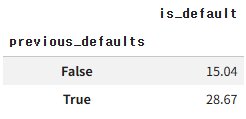

In [4]:
# code here
(df.groupby(df["previous_defaults"] > 0)["is_default"].mean() * 100).round(2).to_csv("default01.csv")


**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 주거 형태에 따른 부도 비율을 백분율 소수점 2자리까지 구하고, 비율이 높은 순으로 정렬하여 출력하세요.

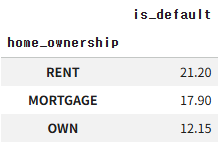

In [5]:
# code here
(df.groupby("home_ownership")["is_default"].mean() * 100).round(2).sort_values(ascending=False).to_csv("default02.csv")

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 부도와 정산 상환 그룹별 (is_default) 재직 연수의 평균을 소수점 2자리까지 구해 주세요.

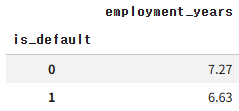

In [6]:
# code here
df.groupby('is_default')['employment_years'].mean().round(2).to_csv("default03.csv")

### **2-2. 데이터 시각화**

현 프로젝트부터는 자신이 데이터를 이해하기 위해 필요한 시각화를 진행하고,기록합니다.
- 따로 가이드라인이 주어지지 않습니다. 경험을 통대로 진행해 주세요.
- 여기서 찾은 인사이트를 활용하여 데이터 전처리를 어떻게 할지 생각해 봅시다.

In [7]:
# 한글 설치
!pip install -q koreanize-matplotlib
import koreanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False

<Axes: xlabel='is_default', ylabel='count'>

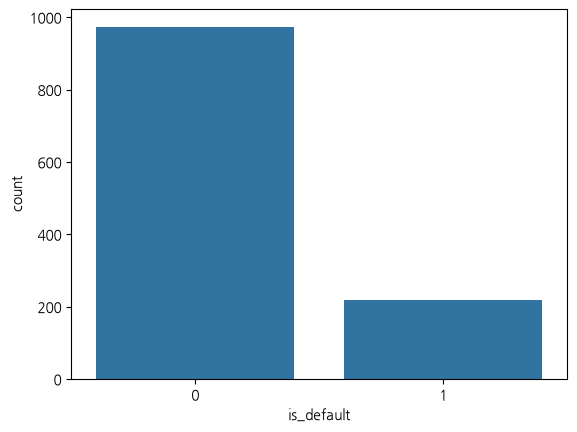

In [8]:
sns.countplot(df, x = "is_default")   # 데이터를 나눌 때 startify 옵션 넣기

<Axes: xlabel='is_default', ylabel='count'>

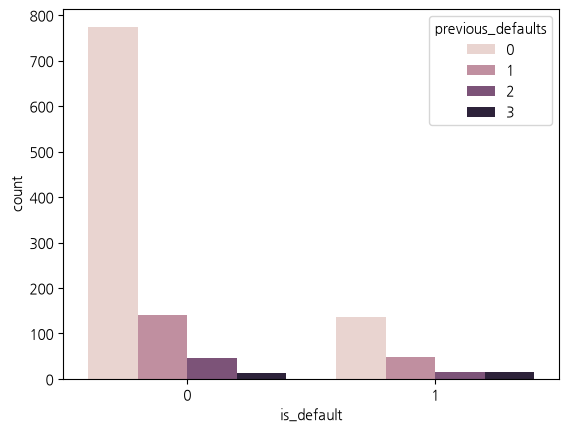

In [9]:
sns.countplot(df, x = "is_default", hue = "previous_defaults")

<Axes: xlabel='is_default', ylabel='count'>

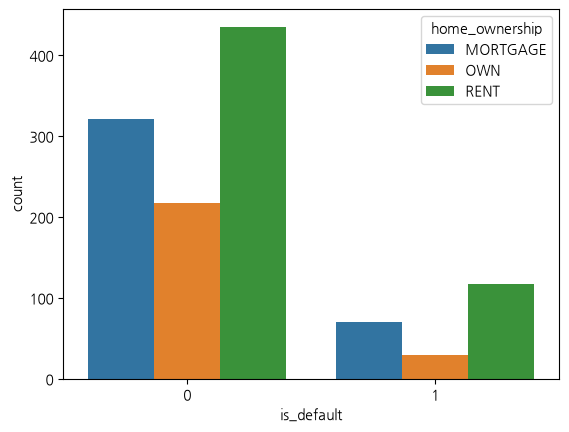

In [10]:
sns.countplot(df, x = "is_default", hue = "home_ownership")

<Axes: xlabel='is_default', ylabel='employment_years'>

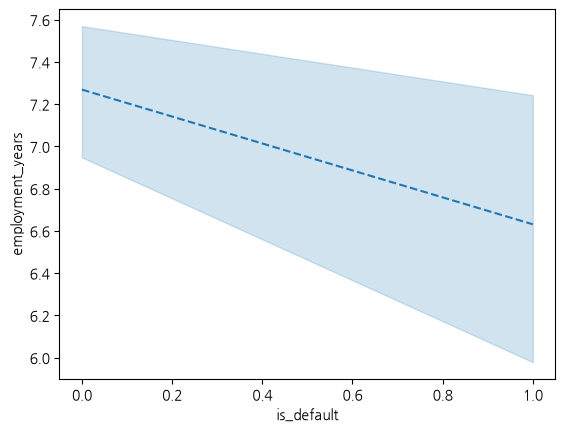

In [11]:
sns.lineplot(df, x = "is_default", y = "employment_years", linestyle = "--")


## **3. 데이터 전처리하기**

현 프로젝트부터는 본인이 필요하다고 생각하는, 그리고 사용할 모델에 따른 전처리 과정을 진행합니다.
- 우리의 목표는 성능이 좋은 가장 "일반적인" 모델을 만드는 것입니다.
- 이것을 잘 할 수 있게 하기 위해 적절한 결측치 처리, 이상치 처리, 인코딩등을 진행해 봅시다.

In [12]:
# 전처리 과정에서 데이터가 망가지면 여기서부터 시작!
df = pd.read_csv('https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/loan.csv')
df.head()

,applicant_id,age,annual_income,employment_years,credit_score,home_ownership,loan_purpose,loan_amount,loan_term_months,interest_rate,debt_to_income_ratio,loan_to_income_ratio,num_credit_lines,previous_defaults,is_default
0,200945,63,72110000.0,10.6,655.0,MORTGAGE,사업자금,17970000.0,48,10.77,0.248,0.249,8,1,0
1,200974,39,23760000.0,8.9,NaN,RENT,의료비,13530000.0,60,12.77,0.497,0.569,6,0,1
2,200151,62,42900000.0,9.2,657.0,MORTGAGE,부채통합,9130000.0,24,12.58,0.105,0.213,5,0,0
3,200124,52,58640000.0,12.7,676.0,OWN,주택개선,1240000.0,36,10.63,0.229,0.021,3,0,0
4,200264,49,64880000.0,6.8,718.0,RENT,주택개선,7920000.0,12,11.56,0.354,0.122,2,0,0


## **중복행 제거**

In [13]:
X = df.drop("is_default", axis = 1)
y = df["is_default"]

In [14]:
X.drop_duplicates()

,applicant_id,age,annual_income,employment_years,credit_score,home_ownership,loan_purpose,loan_amount,loan_term_months,interest_rate,debt_to_income_ratio,loan_to_income_ratio,num_credit_lines,previous_defaults
0,200945,63,72110000.0,10.6,655.0,MORTGAGE,사업자금,17970000.0,48,10.77,0.248,0.249,8,1
1,200974,39,23760000.0,8.9,NaN,RENT,의료비,13530000.0,60,12.77,0.497,0.569,6,0
2,200151,62,42900000.0,9.2,657.0,MORTGAGE,부채통합,9130000.0,24,12.58,0.105,0.213,5,0
3,200124,52,58640000.0,12.7,676.0,OWN,주택개선,1240000.0,36,10.63,0.229,0.021,3,0
4,200264,49,64880000.0,6.8,718.0,RENT,주택개선,7920000.0,12,11.56,0.354,0.122,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1185,201022,55,57510000.0,8.9,657.0,RENT,기타,13770000.0,36,10.90,0.461,0.239,4,0
1186,200790,36,115790000.0,7.9,NaN,OWN,자동차구입,15720000.0,48,12.12,0.129,0.136,6,0
1187,200257,27,45640000.0,5.6,587.0,RENT,부채통합,4560000.0,36,12.89,0.242,0.100,6,0
1188,200969,46,35410000.0,0.0,637.0,MORTGAGE,부채통합,21010000.0,36,10.72,0.540,0.593,5,1


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify= y, random_state=101)

In [16]:
X_train.isnull().sum()

applicant_id             0
age                      0
annual_income           35
employment_years        22
credit_score            36
home_ownership           0
loan_purpose             0
loan_amount              0
loan_term_months         0
interest_rate            0
debt_to_income_ratio    20
loan_to_income_ratio     0
num_credit_lines         0
previous_defaults        0
dtype: int64

### **결측치 처리**

In [17]:
cols = ["annual_income", "employment_years", "credit_score", "debt_to_income_ratio"]

for c in cols:
    fill_vals = X_train[c].median()
    X_train[c] = X_train[c].fillna(fill_vals)
    X_test[c] = X_test[c].fillna(fill_vals)

### **이상치 처리**

In [18]:
def find_whisker(data, columns):
    Q1 = data[columns].quantile(0.25)
    Q3 = data[columns].quantile(0.75)
    iqr = Q3 - Q1
    lower = Q1 - 1.5 * iqr
    upper = Q3 + 1.5 * iqr
    return (lower, upper)

In [19]:
d = {}
for c in cols:
    lower, upper = find_whisker(X_train, c)
    d[c] = (lower, upper)
    outliers = ((X_train[c] < lower) | (X_train[c] > upper)).sum()
    print(f"{c} : {outliers}")

annual_income : 34
employment_years : 2
credit_score : 5
debt_to_income_ratio : 37


In [22]:
for c in cols:
    # train, test cliping 하기
    lower, upper = d[c]
    X_train[c] = X_train[c].clip(lower, upper)
    X_test[c] = X_test[c].clip(lower, upper)

In [23]:
for c in cols:
    lower, upper = find_whisker(X_train, c)
    d[c] = (lower, upper)
    outliers = ((X_train[c] < lower) | (X_train[c] > upper)).sum()
    print(f"{c} : {outliers}")


annual_income : 0
employment_years : 0
credit_score : 0
debt_to_income_ratio : 0


## **인코딩**

In [30]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop='first')

ohe_cols = ["home_ownership", "loan_purpose"]

X_train_encoded = ohe.fit_transform(X_train[ohe_cols])
X_train_encoded - pd.DataFrame(X_train_encoded, columns=ohe.get_feature_names_out(), index=X_train.index)
# X_train_encoded = pd.concat([X_train.drop(ohe_cols, axis = 1), X_train_encoded], axis = 1)

,home_ownership_OWN,home_ownership_RENT,loan_purpose_기타,loan_purpose_부채통합,loan_purpose_사업자금,loan_purpose_의료비,loan_purpose_자동차구입,loan_purpose_주택개선
203,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1049,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
342,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
287,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
713,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
159,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
468,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
647,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
617,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## **4. 모델링**

현 프로젝트부터는 자신이 생각하는 적합한 모델을 선정하여 예측을 진행합니다.
- 따로 가이드라인이 주어지지 않습니다. 경험을 통대로 진행해 주세요.

## **5. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대해 applicant_id에 일치하는 예측 결과를 DataFrame의 "is_default" 컬럼에 기입하고 .csv파일로 저장하여 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/loan_submission.csv

In [20]:
import pandas as pd
submission = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/loan_submission.csv")
submission.head()

,applicant_id,age,annual_income,employment_years,credit_score,home_ownership,loan_purpose,loan_amount,loan_term_months,interest_rate,debt_to_income_ratio,loan_to_income_ratio,num_credit_lines,previous_defaults
0,990001,22,98660000.0,8.7,689.0,MORTGAGE,교육,11940000.0,60,10.63,0.184,0.121,6,0
1,990002,23,52130000.0,7.9,557.0,OWN,자동차구입,10920000.0,60,17.57,0.327,0.209,4,0
2,990003,54,66240000.0,0.0,667.0,MORTGAGE,의료비,14870000.0,24,13.16,0.355,0.224,3,0
3,990004,57,23000000.0,14.0,554.0,MORTGAGE,부채통합,7560000.0,48,13.80,0.302,0.329,6,0
4,990005,55,33280000.0,11.8,750.0,RENT,자동차구입,5480000.0,36,8.88,0.020,0.165,3,0


In [21]:
# code here